<a target="_blank" href="https://storage.googleapis.com/weathernext-public/colabs/WeatherNext_3_Starter_Guide_Zarr_Spatial_Full_Ensemble_on_Google_Cloud_Storage.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Exploring Global Weather Forecasts with Zarr on Google Cloud Storage and WeatherNext 3

**Welcome!** This notebook demonstrates how to load, slice, and visualize a weather forecast dataset available in Zarr format on Google Cloud Storage, generated by Google DeepMind and Google Research's WeatherNext 3 model.

**Dataset Overview**

This dataset offers weather forecasts produced by WeatherNext 3, a state-of-the-art machine learning model developed by Google DeepMind and Google Research. It provides predictions for various weather variables, including temperature, precipitation, wind speed, and more, at a global scale and with a high degree of accuracy. Each forecast consists of 64 ensemble members, representing 64 different possible outcomes.

For precomputed statistics, see the [Statistics Zarr dataset](https://storage.googleapis.com/weathernext-public/colabs/WeatherNext_3_Starter_Guide_Zarr_Spatial_Statistics_on_Google_Cloud_Storage.ipynb).

**Notebook Purpose**

This notebook aims to:

* Familiarize users with the structure and content of the WeatherNext 3 weather forecast dataset in Zarr.
* Demonstrate how to query and analyze this data using the Xarray library's powerful tools and functions.
* Showcase the potential applications of this data for various weather-related tasks, such as forecasting, climate analysis, and risk assessment.

**Copyright Information**

Copyright 2026 Google LLC.

All materials are licensed under the [Creative Commons Attribution 4.0 International License (CC-BY)](https://creativecommons.org/licenses/by/4.0/legalcode).

**Additional Documentation**

[Xarray Library Documentation](https://docs.xarray.dev)


## Import Python Libraries & Setup


In [ ]:
!pip install zarr obstore


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.7/363.7 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 48.4 MB/s eta 0:00:00


In [ ]:
from google.colab import auth
import folium
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
import obstore
from scipy import interpolate as scipy_interpolate
import xarray as xr
import zarr

import warnings
# Suppress FutureWarning
warnings.filterwarnings("ignore", category=FutureWarning)


## Set Google Cloud Project ID


In [ ]:
project_id = '' #@param{type:"string"}


# Weather Forecast Dataset Schema (2026 to Present)

For forecast initializations from 2026 to present, forecasts are published per initialization in GCS under:
`gs://weathernext3_spatial/weathernext_3_0_0/zarr/2026_to_present/<YYYYMMDD_HHhr_XX_preds>/predictions.zarr/`

### Horizon
6-hour inits (00, 06, 12, 18 UTC): with a 360-hour horizon.

Interim 1-hour inits (01–05, 07–11, 13–17, 19–23 UTC): with a 48-hour horizon.


### Dimensions

| Dimension | Description | Typical Size |
| --- | --- | --- |
| `lat_0p05`, `lon_0p05` | High-resolution station grid (0.05°) | 3601 × 7200 |
| `lat_0p1`, `lon_0p1` | Fine grid (0.1°) | 1801 × 3600 |
| `lat_0p25`, `lon_0p25` | Pressure levels grid (0.25°) | 721 × 1440 |
| `lead_subtime` | Hourly offsets within each 6h window (0h to 5h) | 6 |
| `lead_time` | Main forecast step (6h, 12h, ..., 360h) | 60 or 8 |
| `level` | Atmospheric pressure levels (hPa) | 14 |
| `sample` | Ensemble member (0 to 63) | 64 |

### Surface & Single-Level Variables

| Name | Units | Grid | Description |
| --- | --- | --- | --- |
| `dewpoint_temperature_2m` | K | 0.1° | 2m dewpoint temperature (fine grid) |
| `experimental_tp_1hr` | m | 0.1° | Experimental precipitation |
| `high_cloud_cover` | [0-1] | 0.1° | High-altitude cloud cover |
| `imerg_tp_1hr` | m | 0.1° | IMERG calibrated 1-hour precipitation |
| `low_cloud_cover` | [0-1] | 0.1° | Low-altitude cloud cover |
| `mean_sea_level_pressure` | Pa | 0.1° | Mean sea level pressure |
| `medium_cloud_cover` | [0-1] | 0.1° | Mid-altitude cloud cover |
| `sea_surface_temperature` | K | 0.1° | Sea surface temperature |
| `station_head_dewpoint_temperature_2m` | K | 0.05° | 2m dewpoint temperature at station observation locations |
| `station_head_temperature_2m` | K | 0.05° | 2m temperature at station observation locations |
| `surface_solar_radiation_downwards_1hr` | J/m² | 0.1° | Surface solar radiation downwards |
| `temperature_2m` | K | 0.1° | 2m temperature (fine grid) |
| `total_cloud_cover` | [0-1] | 0.1° | Total cloud cover fraction |
| `total_precipitation_1hr` | m | 0.1° | 1-hour total precipitation |
| `total_sky_direct_solar_radiation_at_surface_1hr` | J/m² | 0.1° | Total sky direct solar radiation |
| `u_component_of_wind_100m` | m/s | 0.1° | 100m eastward wind |
| `u_component_of_wind_10m` | m/s | 0.1° | 10m eastward wind |
| `v_component_of_wind_100m` | m/s | 0.1° | 100m northward wind |
| `v_component_of_wind_10m` | m/s | 0.1° | 10m northward wind |

### Multi-Level (Pressure Level) Variables (0.25° Grid)

There are also values for the following variables at various pressure levels (50, 100, 150, 200, 250, 300, 400, 500, 600, 700, 850, 925, 1000 hPa). They are stored along the level dimension:

| Name | Units | Description |
| --- | --- | --- |
| `geopotential` | m²/s² | Geopotential |
| `specific_humidity` | kg/kg | Specific humidity |
| `temperature` | K | Temperature |
| `u_component_of_wind` | m/s | Eastward wind component |
| `v_component_of_wind` | m/s | Northward wind component |
| `vertical_velocity` | Pa/s | Vertical velocity |

### Hourly Pressure level Variables (0.25° Grid)

Most pressure variables are available with 6-hour forecasts, there are a few specific pressure-level variables for which we have hourly forecast data. These are as follows:
| Name | Units | Description |
| --- | --- | --- |
| `geopotential_300hPa` | m²/s² | Geopotential at 300hPa |
| `geopotential_500hPa` | m²/s² | Geopotential at 500hPa |
| `temperature_300hPa` | K | Temperature at 300hPa |
| `temperature_500hPa` | K | Temperature at 500hPa |
| `u_component_of_wind_1000hPa` | m/s | Eastward wind component at 1000hPa |
| `v_component_of_wind_1000hPa` | m/s | Northward wind component at 1000hPa |

# Example Queries

First, open the Zarr dataset in GCS using `obstore` with Requester Pays credentials.


In [ ]:
auth.authenticate_user()

gcs_store = obstore.store.GCSStore(
    bucket="weathernext3_spatial",
    prefix="weathernext_3_0_0/zarr/2026_to_present/20260826_00hr_01_preds/predictions.zarr",
    # This is a Requester Pays bucket, so we pass in the billing project header.
    client_options={
        "default_headers": {
            "x-goog-user-project": project_id
        }
    })
zstore = zarr.storage.ObjectStore(gcs_store)

# Open Zarr dataset
ds = xr.open_zarr(zstore, chunks={})

# Show schema
ds


<xarray.Dataset> Size: 17TB
Dimensions:                                          (sample: 64,
                                                      lead_time: 60,
                                                      lead_subtime: 6,
                                                      lat_0p1: 1801,
                                                      lon_0p1: 3600, level: 13,
                                                      lat_0p25: 721,
                                                      lon_0p25: 1440,
                                                      lat_0p05: 3601,
                                                      lon_0p05: 7200)
Coordinates:
  * sample                                           (sample) int64 512B 0 .....
  * lead_time                                        (lead_time) timedelta64[ns] 480B ...
  * lead_subtime                                     (lead_subtime) timedelta64[ns] 48B ...
  * lat_0p1                                          (lat_0p1) float32 7kB -9...
  * lon_0p1                                          (lon_0p1) float32 14kB 0...
  * level                                            (level) int32 52B 50 ......
  * lat_0p25                                         (lat_0p25) float32 3kB -...
  * lon_0p25                                         (lon_0p25) float32 6kB 0...
  * lat_0p05                                         (lat_0p05) float32 14kB ...
  * lon_0p05                                         (lon_0p05) float32 29kB ...
    datetime                                         (lead_time) datetime64[ns] 480B dask.array<chunksize=(1,), meta=np.ndarray>
    init_time                                        datetime64[ns] 8B ...
Data variables: (12/31)
    dewpoint_temperature_2m                          (sample, lead_time, lead_subtime, lat_0p1, lon_0p1) float32 598GB dask.array<chunksize=(1, 1, 6, 1801, 3600), meta=np.ndarray>
    experimental_tp_1hr                              (sample, lead_time, lead_subtime, lat_0p1, lon_0p1) float32 598GB dask.array<chunksize=(1, 1, 6, 1801, 3600), meta=np.ndarray>
    geopotential                                     (sample, lead_time, level, lat_0p25, lon_0p25) float32 207GB dask.array<chunksize=(1, 1, 1, 721, 1440), meta=np.ndarray>
    geopotential_300hPa                              (sample, lead_time, lead_subtime, lat_0p25, lon_0p25) float32 96GB dask.array<chunksize=(1, 1, 6, 721, 1440), meta=np.ndarray>
    geopotential_500hPa                              (sample, lead_time, lead_subtime, lat_0p25, lon_0p25) float32 96GB dask.array<chunksize=(1, 1, 6, 721, 1440), meta=np.ndarray>
    high_cloud_cover                                 (sample, lead_time, lead_subtime, lat_0p1, lon_0p1) float32 598GB dask.array<chunksize=(1, 1, 6, 1801, 3600), meta=np.ndarray>
    ...                                               ...
    u_component_of_wind_10m                          (sample, lead_time, lead_subtime, lat_0p1, lon_0p1) float32 598GB dask.array<chunksize=(1, 1, 6, 1801, 3600), meta=np.ndarray>
    v_component_of_wind                              (sample, lead_time, level, lat_0p25, lon_0p25) float32 207GB dask.array<chunksize=(1, 1, 1, 721, 1440), meta=np.ndarray>
    v_component_of_wind_1000hPa                      (sample, lead_time, lead_subtime, lat_0p25, lon_0p25) float32 96GB dask.array<chunksize=(1, 1, 6, 721, 1440), meta=np.ndarray>
    v_component_of_wind_100m                         (sample, lead_time, lead_subtime, lat_0p1, lon_0p1) float32 598GB dask.array<chunksize=(1, 1, 6, 1801, 3600), meta=np.ndarray>
    v_component_of_wind_10m                          (sample, lead_time, lead_subtime, lat_0p1, lon_0p1) float32 598GB dask.array<chunksize=(1, 1, 6, 1801, 3600), meta=np.ndarray>
    vertical_velocity                                (sample, lead_time, level, lat_0p25, lon_0p25) float32 207GB dask.array<chunksize=(1, 1, 1, 721, 1440), meta=np.ndarray>

## Exploring Temperature Forecasts for New York City - 24 Hour (Hourly)

This query retrieves hourly 2-meter temperature forecasts for New York, NY for the first 24 hours for all ensemble members for a specific initialization timestamp, using `station_head_temperature_2m` on the 0.05° grid.


In [ ]:
# Note: longitudes in this dataset use 0-360 range.
# Bounding box coordinates for New York City
min_lon, max_lon = 285.74, 286.30
min_lat, max_lat = 40.50, 40.90

nyc_ds = ds[['station_head_temperature_2m']].sel(
    lat_0p05=slice(min_lat, max_lat),
    lon_0p05=slice(min_lon, max_lon)
)

# Show schema for sliced dataset
nyc_ds


<xarray.Dataset> Size: 10MB
Dimensions:                      (sample: 64, lead_time: 60, lead_subtime: 6,
                                  lat_0p05: 9, lon_0p05: 12)
Coordinates:
  * sample                       (sample) int64 512B 0 1 2 3 4 ... 60 61 62 63
  * lead_time                    (lead_time) timedelta64[ns] 480B 0 days 06:0...
  * lead_subtime                 (lead_subtime) timedelta64[ns] 48B -1 days +...
  * lat_0p05                     (lat_0p05) float32 36B 40.5 40.55 ... 40.9
  * lon_0p05                     (lon_0p05) float32 48B 285.8 285.8 ... 286.3
    datetime                     (lead_time) datetime64[ns] 480B dask.array<chunksize=(1,), meta=np.ndarray>
    init_time                    datetime64[ns] 8B ...
Data variables:
    station_head_temperature_2m  (sample, lead_time, lead_subtime, lat_0p05, lon_0p05) float32 10MB dask.array<chunksize=(1, 1, 6, 9, 12), meta=np.ndarray>

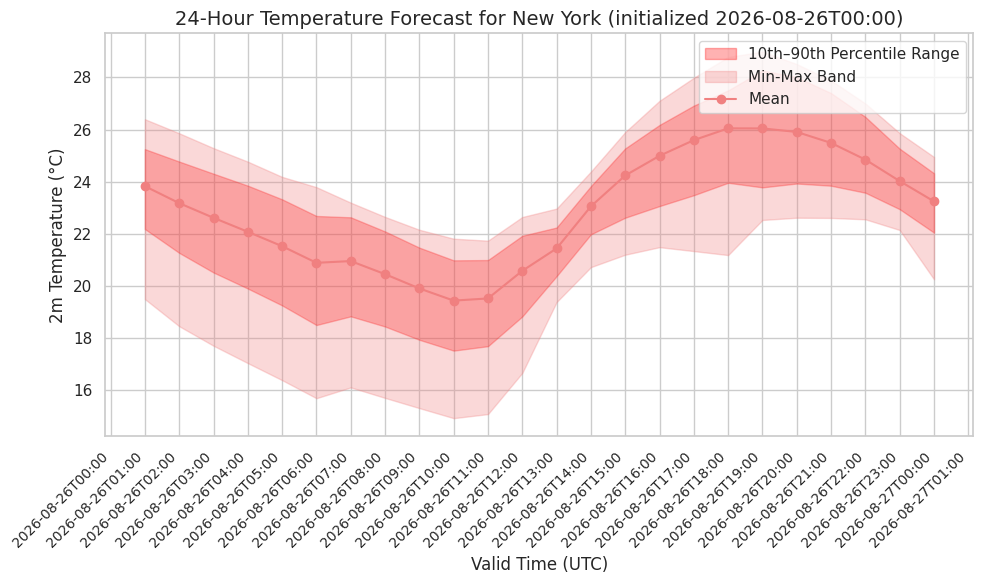

In [ ]:
# Generating this plot can take up to 5 minutes.

# Select lead times covering the first 24 hours (6h, 12h, 18h, 24h)
# Also, only select the first 4 samples for demo purposes
lead_times_24h = [np.timedelta64(h, 'h') for h in [6, 12, 18, 24]]
nyc_24h = nyc_ds['station_head_temperature_2m'].sel(lead_time=lead_times_24h, sample=slice(0, 3))
# Stack lead_time and lead_subtime into hourly steps
nyc_hourly = nyc_24h.stack(step=('lead_time', 'lead_subtime'), create_index=False)
# Compute datetime coordinates for each step
valid_times = (
    ds['init_time'].values
    + nyc_hourly['lead_time'].values
    + nyc_hourly['lead_subtime'].values
)
nyc_hourly = nyc_hourly.assign_coords(valid_time=('step', valid_times))

# Load the data into memory once
nyc_hourly = nyc_hourly.load()

# Compute statistics and convert from Kelvin to Celsius.
nyc_mean = nyc_hourly.mean(dim=('sample', 'lat_0p05', 'lon_0p05')).values.flatten() - 273.15
nyc_min = nyc_hourly.min(dim=('sample', 'lat_0p05', 'lon_0p05')).values.flatten() - 273.15
nyc_max = nyc_hourly.max(dim=('sample', 'lat_0p05', 'lon_0p05')).values.flatten() - 273.15
nyc_p10 = nyc_hourly.quantile(0.1, dim=('sample', 'lat_0p05', 'lon_0p05')).values.flatten() - 273.15
nyc_p90 = nyc_hourly.quantile(0.9, dim=('sample', 'lat_0p05', 'lon_0p05')).values.flatten() - 273.15

# Set up the plot
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

# 10th to 90th percentile uncertainty band
plt.fill_between(valid_times, nyc_p10, nyc_p90, color='red', alpha=0.3, label='10th–90th Percentile Range')

# Min-Max band
plt.fill_between(valid_times, nyc_min, nyc_max, color='lightcoral', alpha=0.3, label='Min-Max Band')

# Ensemble mean line
plt.plot(valid_times, nyc_mean, color='lightcoral', marker='o', label='Mean')

# Labels and axes
plt.xlabel('Valid Time (UTC)', fontsize=12)
plt.ylabel('2m Temperature (°C)', fontsize=12)
# Programmatically determine the init_time in string format for the plot title
forecast_date = np.datetime_as_string(ds['init_time'].values, unit='m')
plt.title(f'24-Hour Temperature Forecast for New York (initialized {forecast_date})', fontsize=14)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%dT%H:%M'))
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=1))
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


## Deterministic Forecasts

### World - 08/26/2026 06:00 Hours

To compute a single deterministic forecast from the 64-member ensemble, compute the ensemble mean across the `sample` dimension for a chosen lead time (e.g. 6 hours).


In [ ]:
# Compute ensemble mean at 6h lead time and 0h subtime offset.
world_avgs = ds.sel(
    lead_time=np.timedelta64(6, 'h'),
    lead_subtime=np.timedelta64(0, 'h'),
    # Select first 4 samples for demo purposes.
    sample=slice(0, 3)
).mean(dim='sample', skipna=True)

world_avgs


<xarray.Dataset> Size: 997MB
Dimensions:                                          (lat_0p1: 1801,
                                                      lon_0p1: 3600, level: 13,
                                                      lat_0p25: 721,
                                                      lon_0p25: 1440,
                                                      lat_0p05: 3601,
                                                      lon_0p05: 7200)
Coordinates:
  * lat_0p1                                          (lat_0p1) float32 7kB -9...
  * lon_0p1                                          (lon_0p1) float32 14kB 0...
  * level                                            (level) int32 52B 50 ......
  * lat_0p25                                         (lat_0p25) float32 3kB -...
  * lon_0p25                                         (lon_0p25) float32 6kB 0...
  * lat_0p05                                         (lat_0p05) float32 14kB ...
  * lon_0p05                                         (lon_0p05) float32 29kB ...
    datetime                                         datetime64[ns] 8B dask.array<chunksize=(), meta=np.ndarray>
    init_time                                        datetime64[ns] 8B ...
    lead_subtime                                     timedelta64[ns] 8B 00:00:00
    lead_time                                        timedelta64[ns] 8B 06:00:00
Data variables: (12/31)
    dewpoint_temperature_2m                          (lat_0p1, lon_0p1) float32 26MB dask.array<chunksize=(1801, 3600), meta=np.ndarray>
    experimental_tp_1hr                              (lat_0p1, lon_0p1) float32 26MB dask.array<chunksize=(1801, 3600), meta=np.ndarray>
    geopotential                                     (level, lat_0p25, lon_0p25) float32 54MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    geopotential_300hPa                              (lat_0p25, lon_0p25) float32 4MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    geopotential_500hPa                              (lat_0p25, lon_0p25) float32 4MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    high_cloud_cover                                 (lat_0p1, lon_0p1) float32 26MB dask.array<chunksize=(1801, 3600), meta=np.ndarray>
    ...                                               ...
    u_component_of_wind_10m                          (lat_0p1, lon_0p1) float32 26MB dask.array<chunksize=(1801, 3600), meta=np.ndarray>
    v_component_of_wind                              (level, lat_0p25, lon_0p25) float32 54MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    v_component_of_wind_1000hPa                      (lat_0p25, lon_0p25) float32 4MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    v_component_of_wind_100m                         (lat_0p1, lon_0p1) float32 26MB dask.array<chunksize=(1801, 3600), meta=np.ndarray>
    v_component_of_wind_10m                          (lat_0p1, lon_0p1) float32 26MB dask.array<chunksize=(1801, 3600), meta=np.ndarray>
    vertical_velocity                                (level, lat_0p25, lon_0p25) float32 54MB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>


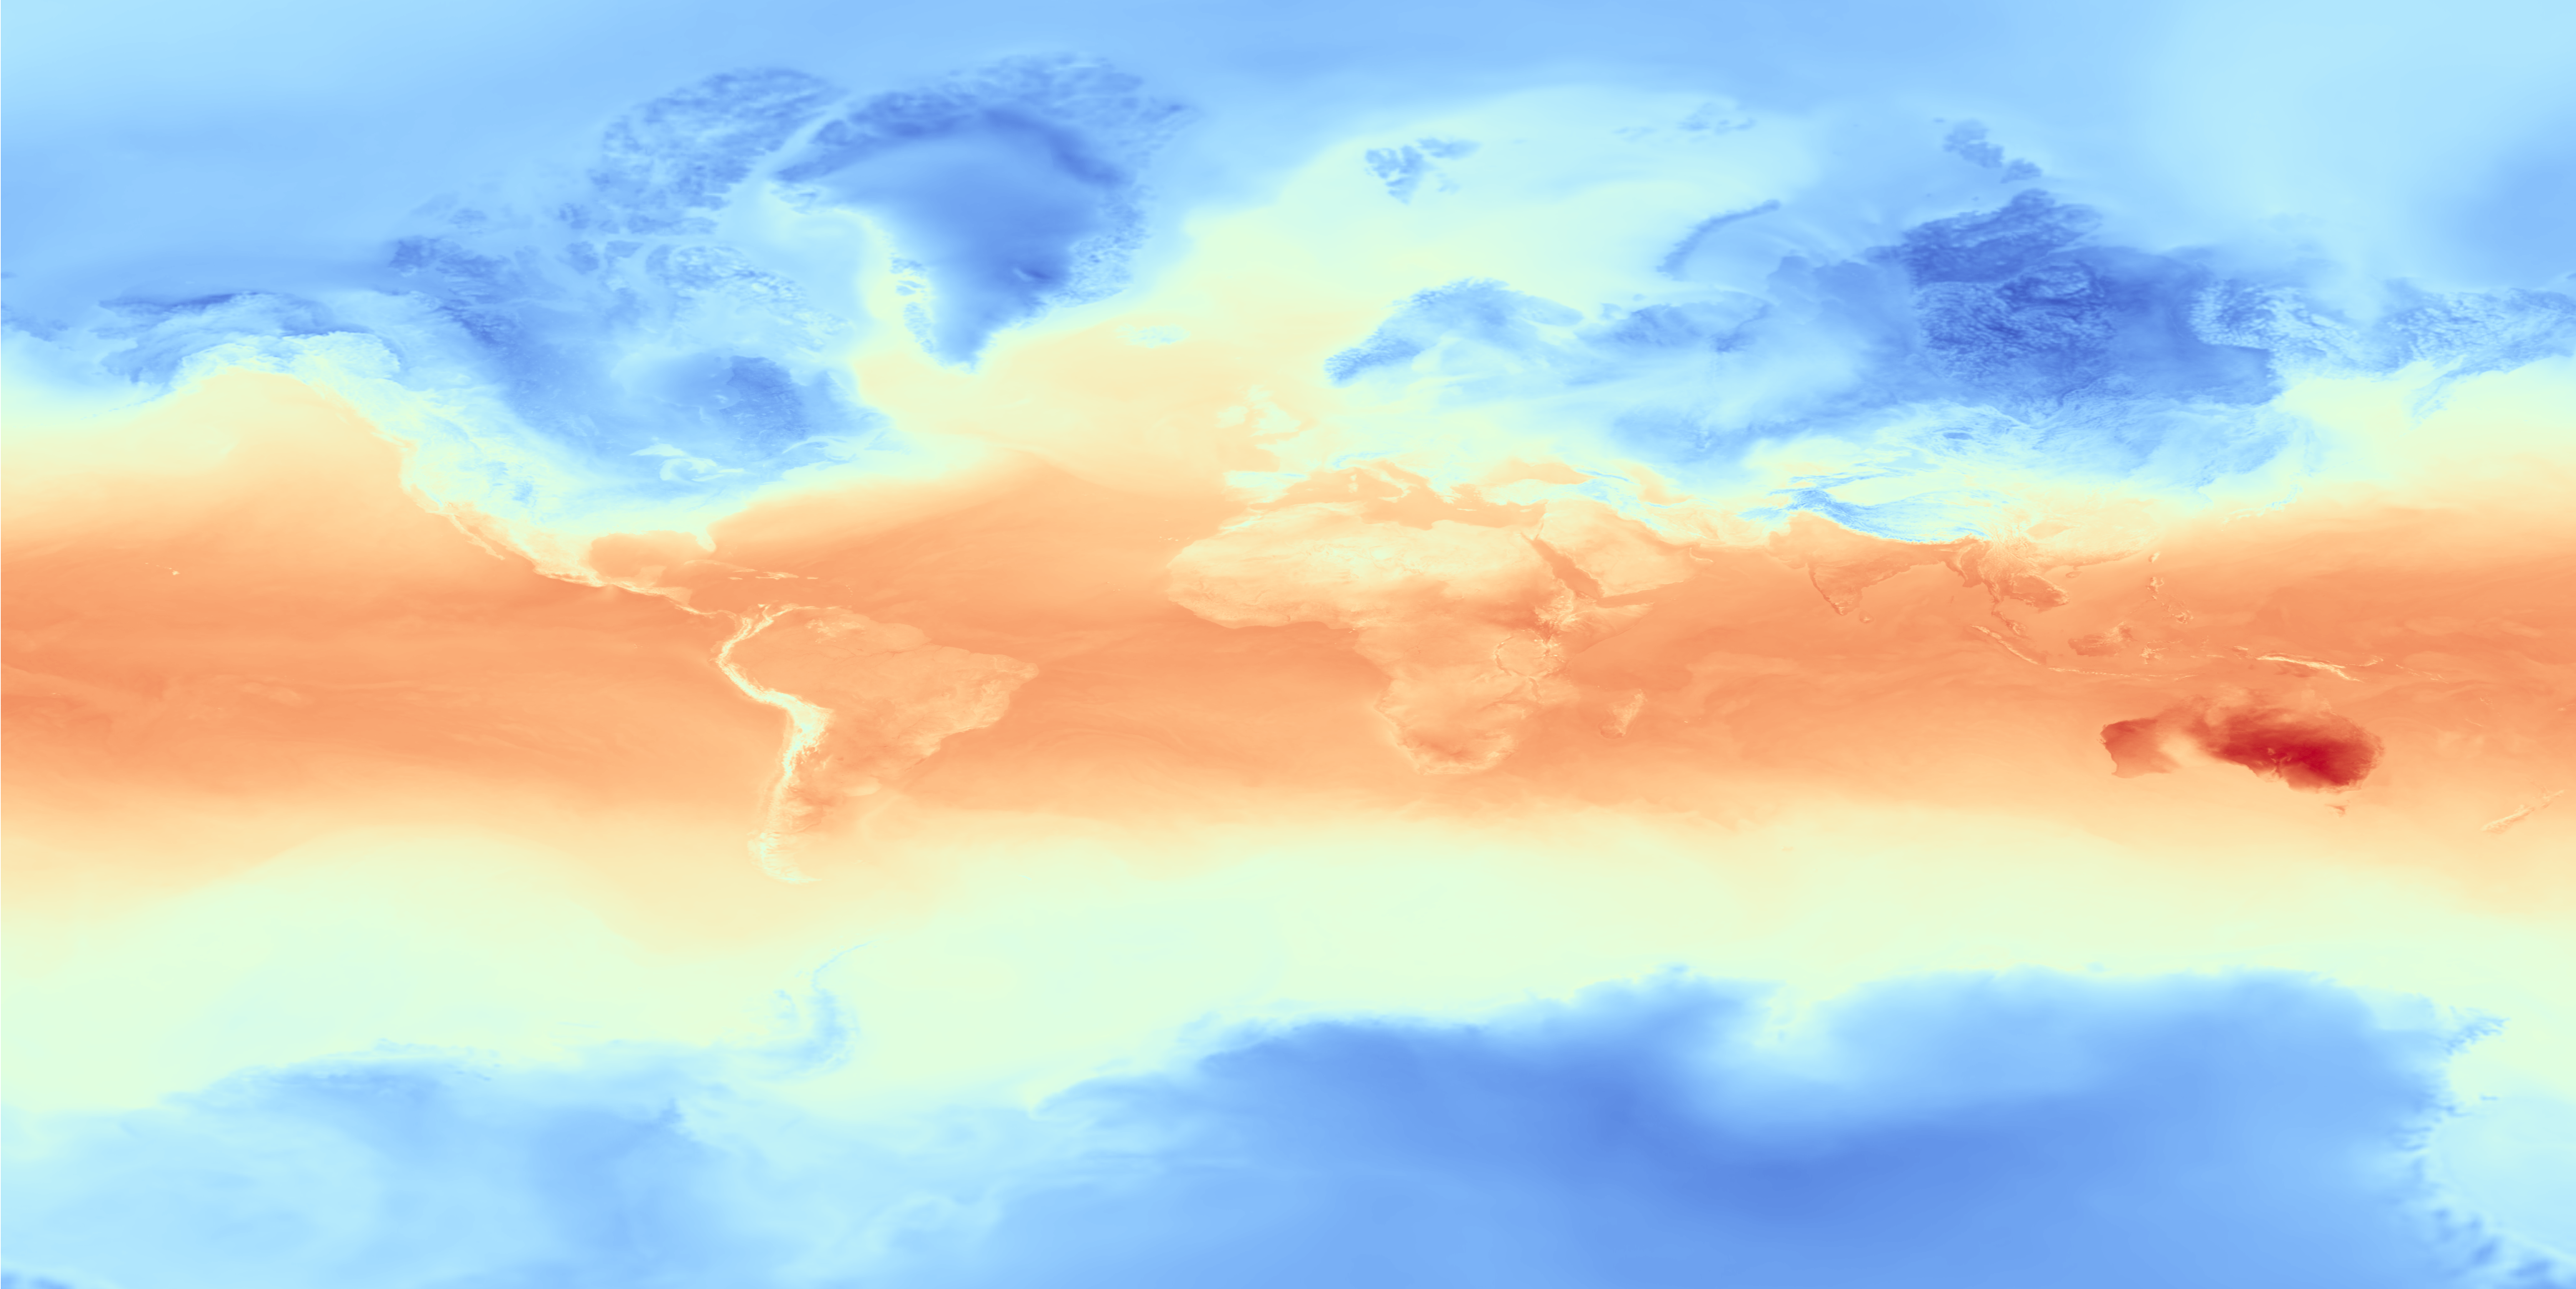

In [ ]:
# Map display options
variable = "temperature_2m"  # @param ["dewpoint_temperature_2m", "experimental_tp_1hr", "geopotential", "high_cloud_cover", "imerg_tp_1hr", "low_cloud_cover", "mean_sea_level_pressure", "medium_cloud_cover", "sea_surface_temperature", "specific_humidity", "station_head_dewpoint_temperature_2m", "station_head_temperature_2m", "surface_solar_radiation_downwards_1hr", "temperature", "temperature_2m", "total_cloud_cover", "total_precipitation_1hr", "total_sky_direct_solar_radiation_at_surface_1hr", "u_component_of_wind", "u_component_of_wind_100m", "u_component_of_wind_10m", "v_component_of_wind", "v_component_of_wind_100m", "v_component_of_wind_10m", "vertical_velocity"]
# If surface-level variable, leave as N/A.
level = "N/A"  # @param ["N/A", 50, 100, 150, 200, 250, 300, 400, 500, 600, 700, 850, 925, 1000]
palette = "coolwarm"  # @param ["coolwarm", "Spectral_r", "viridis", "turbo", "BuPu"]

var_avg = world_avgs[variable]
if level != "N/A" and "level" in var_avg.dims:
  var_avg = var_avg.sel(level=int(level))

# Identify spatial dimensions
if "lat_0p05" in var_avg.dims:
  y_dim, x_dim = "lat_0p05", "lon_0p05"
elif "lat_0p1" in var_avg.dims:
  y_dim, x_dim = "lat_0p1", "lon_0p1"
else:
  y_dim, x_dim = "lat_0p25", "lon_0p25"

# Get lat, lon, and variable avg values as 1d arrays
var_flat = var_avg.stack(lat_lon=(y_dim, x_dim))
x = var_flat[x_dim].values
y = var_flat[y_dim].values
z = var_flat.values

# Convert longitudes from [0, 360) to [-180, 180] for Web Mercator mapping
x = np.where(x > 180, x - 360, x)

nx = var_avg.sizes[x_dim]
ny = var_avg.sizes[y_dim]

# Shift bin edges by half a cell so grid points sit at the center of each bin
dx = 360.0 / nx
dy = 180.0 / ny
lon_bins = np.linspace(-180.0 - dx / 2, 180.0 - dx / 2, nx + 1)
lat_bins = np.linspace(-90.0 - dy / 2, 90.0 + dy / 2, ny + 1)

# Bin data onto the regular grid
weighted_sum, _, _ = np.histogram2d(x, y, bins=(lon_bins, lat_bins), weights=z)
counts, _, _ = np.histogram2d(x, y, bins=(lon_bins, lat_bins))

with np.errstate(divide='ignore', invalid='ignore'):
  grid = np.where(counts > 0, weighted_sum / counts, np.nan)

# Transpose and flip so row 0 is North (+90) and col 0 is West (-180)
grid_equirectangular = np.flipud(grid.T)

# Reproject equirectangular latitudes to Web Mercator latitudes (EPSG:3857)
max_merc_lat = 85.0511287798
y_merc = np.linspace(np.pi, -np.pi, ny)
lat_target = np.degrees(2 * np.arctan(np.exp(y_merc)) - np.pi / 2)
lat_source = np.linspace(90.0, -90.0, ny)

# 1D interpolation along the latitude axis
f_interp = scipy_interpolate.interp1d(
    lat_source,
    grid_equirectangular,
    axis=0,
    kind='linear',
    bounds_error=False,
    fill_value=np.nan,
)
grid_mercator = f_interp(lat_target)

# Normalize data for colormapping
vmin, vmax = np.nanmin(grid_mercator), np.nanmax(grid_mercator)
norm = matplotlib.colors.Normalize(vmin=vmin, vmax=vmax)
cm = matplotlib.colormaps[palette]
rgba_img = cm(norm(grid_mercator))

# Create a base map
m = folium.Map(location=[30, 0], zoom_start=2)

# Add seamless raster overlay aligned with Web Mercator bounds
folium.raster_layers.ImageOverlay(
    image=rgba_img,
    bounds=[[-max_merc_lat, -180.0], [max_merc_lat, 180.0]],
    mercator_project=False,
    opacity=0.5,
).add_to(m)

# Display the map
m